# 12B — Autoencoder 인계 피처표

KODEX 200 CUSUM 463개 정책 가운데 Autoencoder 입력으로 넘길 피처 19개(CUSUM 13 · 보조 열 6)와 판정 근거를 표 그림으로 제시한다.
근거 수치는 `results/ae_handoff_features.csv` (생성 `scripts/t22_ae_handoff.py`) 에서 읽고, 마지막 셀이 12B 결과표와 다시 대조한다.

| 판정 | 뜻 |
|---|---|
| 넘김 | 독립 값 군집의 대표이거나 SVR 에 의존하지 않는 기준. 변형이 많은 군집은 대표 하나만 |
| 조건부 | X1 자기정규화 Page — 결과를 본 뒤 추가한 탐색 통계량이라 2026 이후 자료·다른 ETF 검증 뒤 사용 |
| 마스크 | 연속 신호가 아니라 결측·재학습 경계·창에 남은 충격을 표시하는 열 |
| 제외 | 대표와 같은 신호(초기화 변형 ρ = 1.00)이거나 잔차 척도 때문에 상태가 저절로 쌓이는 통계량 |

읽는 법: 시간 규모 눈금의 파란 막대 = 최근 w일 이동창, 주황 막대 = X1 이 척도를 재는 과거 구간(t−252 ~ t−61), 회색 = 시작부터 누적.
예측 개선은 관측 변동성 4종 + SVR 예측변동성 기준 대비 표본외 상대 MSE 감소이고(한 해씩 빼고 시험), 정책마다 유효일이 달라 공통 846일 값을 옅은 막대로 함께 그렸다.
국면 반응은 확대·감소·높은 수준 유지 국면의 과거 백분위 평균에서 안정 국면을 뺀 값이다 (위 = 그 국면에서 높아짐).

In [1]:
# 새 커널 첫 셀: BLAS 스레드를 NumPy 로드 전에 1로 고정해 결과를 결정적으로 만든다.
import os  # 환경변수 설정
import sys  # 인터프리터·모듈 경로 확인
from pathlib import Path  # 저장소 상대 경로

for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):  # 네 BLAS 계열 변수
    os.environ[key] = "1"  # 다중 스레드 합산 순서에 따른 비트 차이를 막는다
assert "numpy" not in sys.modules, "새 커널에서 첫 셀부터 실행해야 합니다"  # 숨은 커널 상태 금지
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/t22_k200_overlay_v1.json").is_file())  # 저장소 루트 탐색
sys.path.insert(0, str(ROOT / "src"))  # 이 작업트리의 r2h 패키지를 우선 사용

import contextlib  # 단계 출력 가두기
import hashlib  # 파일 지문
import importlib.metadata as metadata  # 설치 패키지 버전 조회
import importlib.util  # 단계 스크립트 불러오기
import io  # 출력 버퍼
import json  # 설정·캡션
import platform  # Python 버전
import time  # 단계 소요 시간

import matplotlib  # 그림 백엔드
matplotlib.use("Agg")  # 화면 없이 파일로 저장
import numpy as np  # 수치 배열
import pandas as pd  # 결과표
from IPython.display import Image, Markdown, display  # 표·그림·문단 출력
import matplotlib.pyplot as plt  # 그림 기본 설정
from matplotlib import font_manager  # 한글 글꼴 등록

FONT_FILE = Path("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")  # 한글 도판용 나눔고딕
assert FONT_FILE.is_file(), "한글 도판 렌더링을 위한 나눔고딕 파일이 없습니다"  # 글꼴 없으면 중단
font_manager.fontManager.addfont(str(FONT_FILE))  # matplotlib 글꼴 목록에 등록
plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(FONT_FILE)).get_name()  # 한글 글꼴 사용
plt.rcParams["axes.unicode_minus"] = False  # 음수 기호 깨짐 방지

# 12번과 같은 고정 환경 (user-site 차단 포함).
EXPECTED_ENV = {"python": "3.12.3", "numpy": "2.5.4", "pandas": "3.0.6", "scipy": "1.18.1", "matplotlib": "3.11.2", "scikit-learn": "1.9.1"}  # 고정 환경
ACTUAL_ENV = {"python": platform.python_version(), **{k: metadata.version(k) for k in ("numpy", "pandas", "scipy", "matplotlib", "scikit-learn")}}  # 실제 커널
assert ACTUAL_ENV == EXPECTED_ENV, f"실행 환경 불일치: {ACTUAL_ENV}"  # 버전 불일치는 재현 실패
assert ".local" not in np.__file__, np.__file__  # user-site 패키지 차단
pd.set_option("display.width", 220)  # 표 줄바꿈 완화
pd.set_option("display.max_columns", 40)  # 열 생략 완화
pd.set_option("display.max_rows", 60)  # 행 생략 완화

from r2h.k200_overlay import figures as G  # 12B 그림 (대표 쌍·라벨)

assert Path(sys.modules["r2h"].__file__).resolve().is_relative_to((ROOT / "src").resolve())  # 다른 트리의 r2h 금지
BASE = ROOT / "research/k200_cusum_overlay_12b"  # 12B 산출물 폴더
RES = BASE / "results"  # 결과표
FIGDIR = BASE / "figures"  # 그림 (PNG 320dpi + SVG)
OUT = ROOT / "outputs/t22"  # 일별 장형 Parquet (Git 제외)


def sha(p):  # 파일 SHA256
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()  # 바이트 단위 지문


def preview(path, width=1100):  # 노트북 용량을 줄이는 축소 미리보기 (원본은 figures/)
    from PIL import Image as PILImage  # 이미지 축소
    im = PILImage.open(path)  # 320dpi 원본
    im.thumbnail((width, width * 3))  # 가로 1100px 이하로 축소
    buf = io.BytesIO()  # 출력 버퍼
    im.save(buf, format="PNG", optimize=True)  # PNG 로 다시 저장
    return buf.getvalue()  # 바이트 반환


# 계약 동결 지문: 국면·이벤트 정의는 계산 전에 커밋한 그대로여야 한다.
FREEZE = dict(reversed(line.split(maxsplit=1)) for line in (BASE / "CONTRACT_FREEZE_SHA256.txt").read_text().splitlines())  # 경로 → 해시
assert all(sha(ROOT / p) == h for p, h in FREEZE.items()), "12B-lock-1 계약 파일 변경"  # 동결본과 같아야 한다
# 12번 기준 커밋 c8998a6 의 추적 파일 915개 지문 — 실행 전후 모두 같아야 한다 (G0).
PROT = [line.split(maxsplit=1) for line in (BASE / "evidence/PROTECTED_12_SHA256.txt").read_text().splitlines()]  # (해시, 경로)
bad = [p for h, p in PROT if sha(ROOT / p) != h]  # 바뀐 보호 파일
assert not bad, f"보호 파일 변경: {bad[:5]}"  # 12번 산출물은 읽기만
INPUTS = [line.split(maxsplit=1) for line in (BASE / "evidence/INPUT_SHA256.txt").read_text().splitlines()]  # 동결 입력 (Feature Store·귀무표·원자료)
bad_in = [p for h, p in INPUTS if sha(ROOT / p) != h]  # 바뀐 입력
assert not bad_in, f"동결 입력 변경: {bad_in}"  # 12번 Feature Store 를 그대로 써야 한다
print("작업트리:", ROOT, "| 12번 보호", len(PROT), "개 · 입력", len(INPUTS), "개 불변 | 환경", ACTUAL_ENV)  # 검증 요약

작업트리: /home/sieg/projects-wsl/hongik_univ_26_2/SA/1019/R2H_K200_CUSUM_12 | 12번 보호 915 개 · 입력 14 개 불변 | 환경 {'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'scikit-learn': '1.9.1'}


In [2]:
# 그림 저장·표시 도우미와 근거 표 원본.
def show_png(fig, path):  # PNG(200dpi) 로 저장하고 노트북에 표시
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white", metadata={"Software": None})  # 결정적 PNG
    plt.close(fig)  # 메모리 해제
    display(Image(data=preview(path, width=1400)))  # 축소 미리보기 표시
    print("저장:", path.relative_to(ROOT))  # 경로


display(pd.read_csv(RES / "ae_handoff_features.csv").drop(columns=["label"]).round(3))  # 그림의 근거가 되는 표 (원본 수치)

,feature,experiment_id,group,time_scale,form,verdict,reason,valid_days,na_days,first_valid,value_cluster,cluster_size,rho_vol20_level,contrast_expanding,contrast_contracting,contrast_high_persist,rho_lag0,rel_mse_gain,years_positive,rel_mse_gain_common846,kind
0,cusum_cos_w20,E2_w20,SVR 잔차 이동 CoS,20일,원시 T + 과거 백분위,KEEP,"w60 과 ρ 0.07 — 짧은 기억 · 증분은 거의 0 (+0.2%, 공통일 +0...",1454.0,19.0,2020-01-31,38.0,2.0,0.020,-0.042,-0.075,-0.014,0.149,0.002,3.0,0.007,CUSUM
1,cusum_cos_w60,B1,SVR 잔차 이동 CoS,60일,원시 T + 과거 백분위,KEEP,117개 CoS 군집 대표 — 증분은 음수(−1.6%) · 기준 시간 규모로만 유지,1414.0,59.0,2020-03-27,1.0,117.0,-0.130,0.194,0.130,0.001,-0.028,-0.016,0.0,-0.023,CUSUM
2,cusum_cos_w120,E2_w120,SVR 잔차 이동 CoS,120일,원시 T + 과거 백분위,KEEP,"독립 군집 · 증분 불안정 (전체 +2.4%, 공통일 −2.9%)",1354.0,119.0,2020-06-25,47.0,1.0,-0.124,0.027,0.033,-0.060,0.008,0.024,4.0,-0.029,CUSUM
3,cusum_cos_w252,E2_w252,SVR 잔차 이동 CoS,252일,원시 T + 과거 백분위,KEEP,"긴 기억(창 이월) · CoS 중 증분 최대 (+3.9%, 공통일 +5.7%)",1222.0,251.0,2021-01-07,48.0,1.0,-0.189,-0.071,-0.089,-0.135,0.164,0.039,3.0,0.057,CUSUM
4,cusum_raw_cos_w60,E3_raw_rolling_cos,원수익률 이동 CoS,60일,원시 T,KEEP,SVR 비의존 기준 · 확대 반응 최대(+0.27) · 증분은 음수(−1.1%),1414.0,59.0,2020-03-27,50.0,1.0,-0.050,0.270,0.136,0.035,0.027,-0.011,1.0,-0.033,CUSUM
5,cusum_page_down,E3_page_down,Page 하방,누적,자유 상태 + 과거 백분위,KEEP,"107개 하방 군집 대표 · 증분 +3.5% (4/5년, 공통일 +2.2%)",1473.0,0.0,2020-01-02,2.0,107.0,-0.106,-0.024,0.050,-0.025,-0.455,0.035,4.0,0.022,CUSUM
6,cusum_x1_down,X1_page_down_sn,X1 자기정규화 Page,"누적 · 기준 [t−252, t−61]",방향별 상태,CONDITIONAL,탐색 통계량 · 증분 +3.8% (공통일 +4.5%) · 2020-09-21 전 NA,1293.0,180.0,2020-09-21,71.0,1.0,-0.376,-0.068,0.059,-0.177,-0.453,0.038,3.0,0.045,CUSUM
7,cusum_x1_two,X1_page_two_sn,X1 자기정규화 Page,"누적 · 기준 [t−252, t−61]",상·하방 상태 분리,CONDITIONAL,증분 +8.1% (공통일 +2.7%) · 단일 군집 · 2020-09-21 전 NA,1293.0,180.0,2020-09-21,72.0,1.0,-0.271,0.008,0.067,-0.121,-0.149,0.081,3.0,0.027,CUSUM
8,cusum_page_up,E3_page_up,Page 상방,누적,자유 상태,DROP,잔차 척도 표류 (e² > 1.386 에서 저절로 누적) · 전체 +2.0% 이나 ...,1473.0,0.0,2020-01-02,4.0,23.0,0.578,0.195,0.057,0.254,0.444,0.020,3.0,-0.086,CUSUM
9,cusum_x1_up,X1_page_up_sn,X1 자기정규화 Page,누적,상태,DROP,증분 음수 (−1.1%) · 실데이터 2021–2025 경보 0,1293.0,180.0,2020-09-21,73.0,1.0,0.262,0.119,-0.049,0.147,0.346,-0.011,3.0,-0.012,CUSUM


## 1. CUSUM 피처 13개

findfont: Failed to find font weight bold for NanumGothic, now using 600.


findfont: Failed to find font weight bold for NanumGothic, now using 600.


findfont: Failed to find font weight bold for NanumGothic, now using 600.


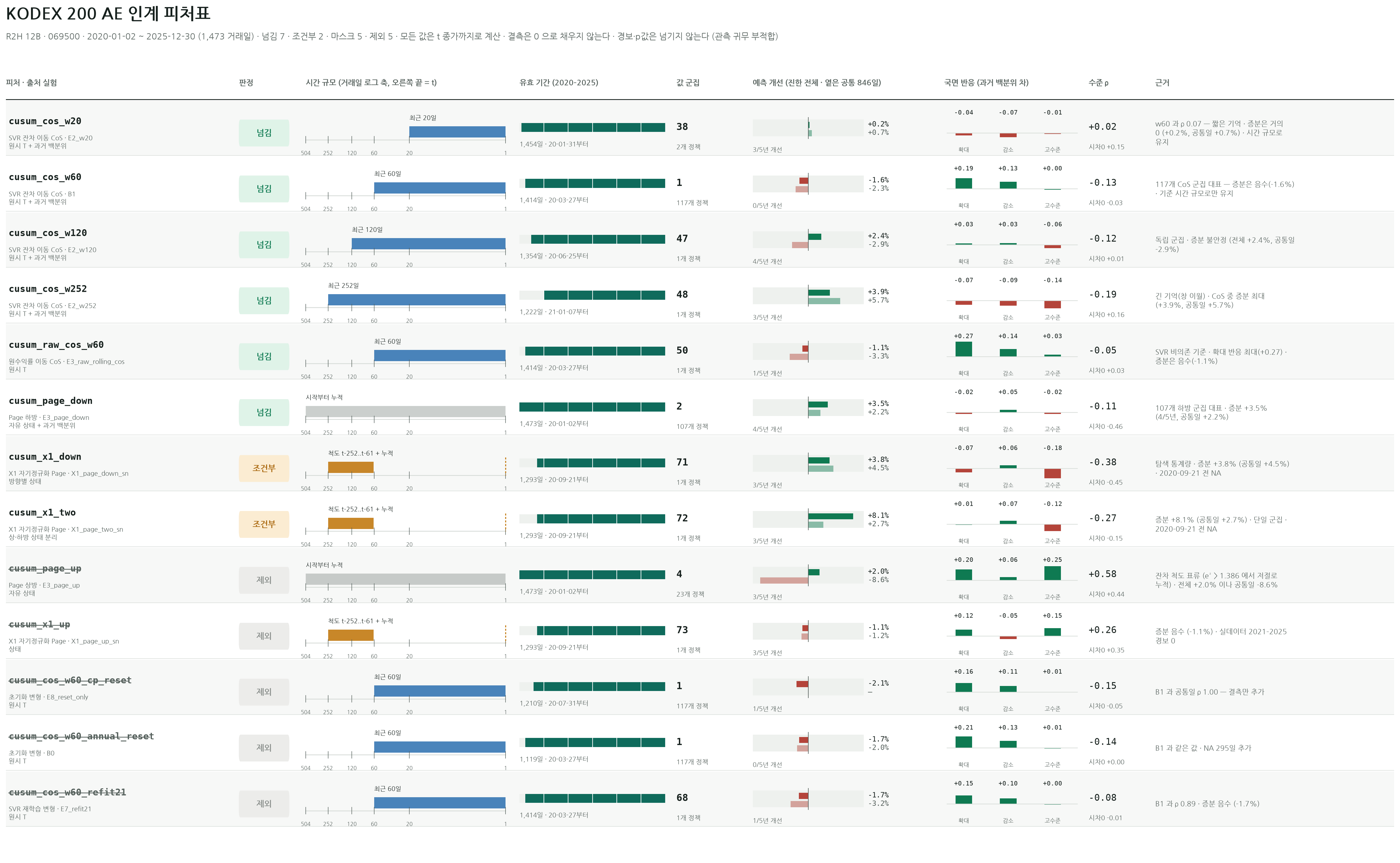

저장: research/k200_cusum_overlay_12b/figures_ae/AE01_인계_피처표.png


In [3]:
# 표 그림 AE01 — 한 줄 = 피처 하나: 판정 칩 · 시간 규모 눈금 · 유효 기간 · 값 군집 · 예측 개선 · 국면 반응 · 수준 ρ · 근거.
import math  # 로그 눈금
import textwrap  # 근거 줄바꿈
from matplotlib.patches import FancyBboxPatch, Rectangle  # 칩·막대

F = pd.read_csv(RES / "ae_handoff_features.csv")  # 인계 피처표 (근거 수치는 12B 결과표에서 생성)
CU = F[F["kind"] == "CUSUM"].reset_index(drop=True)  # CUSUM 피처 13개
SU = F[F["kind"] == "SUPPORT"].reset_index(drop=True)  # 보조 열 6개
FA = BASE / "figures_ae"  # 저장 폴더
FA.mkdir(exist_ok=True)  # 없으면 만든다
plt.rcParams["svg.hashsalt"] = "t22_ae_handoff"  # 결정적 SVG
INK, INK2, RULE, SOFT = "#16201d", "#55605c", "#d8ddd9", "#eef1ee"  # 글자·보조 글자·구분선·바탕
VC = {"KEEP": ("#0f7a52", "#dff3e8", "넘김"), "CONDITIONAL": ("#a8650a", "#fbecd2", "조건부"), "MASK": ("#3d5a8a", "#e3eaf6", "마스크"), "DROP": ("#8a8f8c", "#ececea", "제외")}  # 판정 색
POS, NEG, WIN, REF = "#0f7a52", "#b4443a", "#2a6fb0", "#c27a12"  # 양수·음수·이동창·X1 기준 구간
WINDOW = {"E2_w20": 20, "B1": 60, "E2_w120": 120, "E2_w252": 252, "E3_raw_rolling_cos": 60, "E8_reset_only": 60, "B0": 60, "E7_refit21": 60}  # 실험별 창 길이
D0, D1 = pd.Timestamp("2020-01-02"), pd.Timestamp("2025-12-30")  # 평가 구간
COLS = {"name": (0.0, 16.5), "verdict": (16.8, 21.0), "scale": (21.6, 36.0), "cov": (37.0, 47.5), "clu": (48.3, 53.0), "inc": (53.8, 66.8), "reg": (67.6, 77.4), "rho": (78.0, 82.2), "why": (82.8, 100.0)}  # 열 위치 (가로 0–100)


def chip(ax, x, y, v, w=3.6):  # 판정 칩
    fg, bg, lab = VC[v]  # 색·이름
    ax.add_patch(FancyBboxPatch((x, y - 0.22), w, 0.44, boxstyle="round,pad=0.02,rounding_size=0.12", fc=bg, ec="none"))  # 바탕
    ax.text(x + w / 2, y, lab, ha="center", va="center", fontsize=10, color=fg, fontweight="bold")  # 이름


def ruler(ax, y, eid):  # 시간 규모 눈금: 1–504 거래일 로그 축, 오른쪽 끝이 t
    x0, x1 = COLS["scale"]  # 열 범위
    pos = lambda v: x0 + (x1 - x0) * (1 - math.log(v) / math.log(504))  # 거래일 → 가로 위치
    ax.plot([x0, x1], [y + 0.12, y + 0.12], color=RULE, lw=1)  # 축선
    for t in (1, 20, 60, 120, 252, 504):  # 눈금
        ax.plot([pos(t)] * 2, [y + 0.06, y + 0.18], color=INK2, lw=0.6)  # 눈금선
        ax.text(pos(t), y + 0.36, str(t), ha="center", va="center", fontsize=6.5, color=INK2)  # 눈금 숫자
    if eid in WINDOW:  # 이동창
        w = WINDOW[eid]  # 창 길이
        ax.add_patch(Rectangle((pos(w), y - 0.12), pos(1) - pos(w), 0.2, fc=WIN, ec="none", alpha=0.85))  # 최근 w일
        ax.text(pos(w), y - 0.27, f"최근 {w}일", ha="left", va="center", fontsize=7.5, color=INK)  # 라벨
    elif eid.startswith("X1"):  # X1 기준 구간 + 누적
        ax.add_patch(Rectangle((pos(252), y - 0.12), pos(61) - pos(252), 0.2, fc=REF, ec="none", alpha=0.9))  # 척도 구간
        ax.plot([pos(1)] * 2, [y - 0.2, y + 0.12], color=REF, lw=1.2, ls=(0, (2, 1.5)))  # 오늘
        ax.text(pos(252), y - 0.27, "척도 t-252..t-61 + 누적", ha="left", va="center", fontsize=7.5, color=INK)  # 라벨
    else:  # Page 누적
        ax.add_patch(Rectangle((pos(504), y - 0.12), pos(1) - pos(504), 0.2, fc=INK2, ec="none", alpha=0.3))  # 시작부터 누적
        ax.text(pos(504), y - 0.27, "시작부터 누적", ha="left", va="center", fontsize=7.5, color=INK)  # 라벨


def coverage(ax, y, r):  # 유효 기간 막대 (2020–2025)
    x0, x1 = COLS["cov"]  # 열 범위
    f = pd.Timestamp(r["first_valid"])  # 첫 유효일
    xf = x0 + (x1 - x0) * (f - D0).days / (D1 - D0).days  # 시작 위치
    ax.add_patch(Rectangle((x0, y - 0.18), x1 - x0, 0.16, fc=SOFT, ec="none"))  # 전체 기간
    ax.add_patch(Rectangle((xf, y - 0.18), x1 - xf, 0.16, fc="#0f6b5c", ec="none"))  # 유효 기간
    for yr in range(2021, 2026):  # 연 경계
        xx = x0 + (x1 - x0) * (pd.Timestamp(f"{yr}-01-01") - D0).days / (D1 - D0).days  # 위치
        ax.plot([xx, xx], [y - 0.2, y], color="white", lw=0.8)  # 흰 구분선
    ax.text(x0, y + 0.2, f"{int(r['valid_days']):,}일 · {r['first_valid'][2:]}부터", ha="left", va="center", fontsize=8, color=INK2)  # 유효일·시작일


def increment(ax, y, r):  # 예측 개선: 진한 = 전체, 옅은 = 공통 846일 (±10% 축)
    x0, x1 = COLS["inc"][0], COLS["inc"][0] + 8.0  # 막대 영역
    xm = (x0 + x1) / 2  # 0 위치
    ax.add_patch(Rectangle((x0, y - 0.24), x1 - x0, 0.3, fc=SOFT, ec="none"))  # 바탕
    ax.plot([xm, xm], [y - 0.28, y + 0.1], color=INK2, lw=0.7)  # 0 선
    for k, (col, a) in enumerate((("rel_mse_gain", 1.0), ("rel_mse_gain_common846", 0.45))):  # 두 비교
        v = r[col]  # 값
        yy = y - 0.2 + k * 0.15  # 줄 위치
        if pd.notna(v):  # 값이 있으면
            w = min(abs(v) / 0.10, 1) * (x1 - x0) / 2  # 길이
            ax.add_patch(Rectangle((xm if v >= 0 else xm - w, yy), w, 0.11, fc=POS if v >= 0 else NEG, alpha=a, ec="none"))  # 막대
        ax.text(x1 + 0.3, yy + 0.05, "—" if pd.isna(v) else f"{v * 100:+.1f}%", ha="left", va="center", fontsize=8.5, color=INK if k == 0 else INK2, family="monospace")  # 숫자
    ax.text(x0, y + 0.3, f"{int(r['years_positive'])}/5년 개선", ha="left", va="center", fontsize=7.5, color=INK2)  # 개선 연수


def regime(ax, y, r):  # 국면 반응 3종 (±0.3 축)
    x0, _ = COLS["reg"]  # 열 시작
    for k, (lab, col) in enumerate((("확대", "contrast_expanding"), ("감소", "contrast_contracting"), ("고수준", "contrast_high_persist"))):  # 국면마다
        v = r[col]  # 값
        xc = x0 + 1.4 + k * 3.2  # 막대 중심
        h = min(abs(v) / 0.3, 1) * 0.3  # 높이
        ax.add_patch(Rectangle((xc - 0.6, y - h if v >= 0 else y), 1.2, max(h, 0.015), fc=POS if v >= 0 else NEG, ec="none"))  # 막대 (위 = 양수)
        ax.text(xc, y - 0.36, f"{v:+.2f}", ha="center", va="center", fontsize=7.5, color=INK, family="monospace")  # 값
        ax.text(xc, y + 0.3, lab, ha="center", va="center", fontsize=7, color=INK2)  # 국면 이름
    ax.plot([x0 + 0.2, x0 + 9.6], [y, y], color=RULE, lw=0.8)  # 0 선


n = len(CU)  # 행 수
fig = plt.figure(figsize=(24, 2.6 + 0.95 * n))  # 큰 표 그림
ax = fig.add_axes([0.01, 0.01, 0.98, 0.9])  # 표 영역
ax.set_xlim(0, 100)  # 가로 좌표
ax.set_ylim(n + 0.1, -1.1)  # 세로 좌표 (위가 0)
ax.axis("off")  # 축 숨김
heads = dict(name="피처 · 출처 실험", verdict="판정", scale="시간 규모 (거래일 로그 축, 오른쪽 끝 = t)", cov="유효 기간 (2020–2025)", clu="값 군집")  # 열 제목
heads.update(inc="예측 개선 (진한 전체 · 옅은 공통 846일)", reg="국면 반응 (과거 백분위 차)", rho="수준 ρ", why="근거")  # 열 제목 (계속)
for k, (a, b) in COLS.items():  # 열마다
    ax.text(a, -0.75, heads[k], ha="left", va="center", fontsize=9.5, color=INK2, fontweight="bold")  # 머리글
ax.plot([0, 100], [-0.45, -0.45], color=INK, lw=1)  # 머리 구분선
for i, r in CU.iterrows():  # 피처마다
    y = i + 0.15  # 행 중심
    drop = r["verdict"] == "DROP"  # 제외 행
    if i % 2 == 0:  # 줄무늬
        ax.add_patch(Rectangle((0, i - 0.43), 100, 0.98, fc="#f7f8f7", ec="none", zorder=0))  # 옅은 바탕
    ax.text(0.2, y - 0.2, r["feature"], ha="left", va="center", fontsize=11, color=INK2 if drop else INK, family="monospace", fontweight="bold")  # 피처 이름
    if drop:  # 제외는 취소선
        ax.plot([0.2, 0.2 + 0.39 * len(r["feature"])], [y - 0.2, y - 0.2], color=INK2, lw=0.9)  # 취소선
    ax.text(0.2, y + 0.02, f"{r['group']} · {r['experiment_id']}\n{r['form']}", ha="left", va="top", fontsize=8, color=INK2, linespacing=1.2)  # 그룹·실험 ID·형태
    chip(ax, COLS["verdict"][0], y, r["verdict"])  # 판정
    ruler(ax, y, r["experiment_id"])  # 시간 규모
    coverage(ax, y, r)  # 유효 기간
    ax.text(COLS["clu"][0], y - 0.1, f"{int(r['value_cluster'])}", ha="left", va="center", fontsize=12, color=INK, family="monospace", fontweight="bold")  # 군집 번호
    ax.text(COLS["clu"][0], y + 0.25, f"{int(r['cluster_size'])}개 정책", ha="left", va="center", fontsize=8, color=INK2)  # 군집 크기
    increment(ax, y, r)  # 예측 개선
    regime(ax, y, r)  # 국면 반응
    ax.text(COLS["rho"][0], y - 0.1, f"{r['rho_vol20_level']:+.2f}", ha="left", va="center", fontsize=11, color=INK, family="monospace")  # 수준 ρ
    ax.text(COLS["rho"][0], y + 0.25, f"시차0 {r['rho_lag0']:+.2f}", ha="left", va="center", fontsize=8, color=INK2)  # 시차 0 상관
    ax.text(COLS["why"][0], y, "\n".join(textwrap.wrap(r["reason"].replace("−", "-"), 30)), ha="left", va="center", fontsize=8.5, color=INK2, linespacing=1.3)  # 근거
    ax.plot([0, 100], [i + 0.55, i + 0.55], color=RULE, lw=0.6)  # 행 구분선
cnt = F["verdict"].value_counts()  # 판정별 수
fig.text(0.01, 0.975, "KODEX 200 AE 인계 피처표", fontsize=20, fontweight="bold", color=INK, va="top")  # 제목
fig.text(0.01, 0.945, f"R2H 12B · 069500 · 2020-01-02 ~ 2025-12-30 (1,473 거래일) · 넘김 {cnt.get('KEEP', 0)} · 조건부 {cnt.get('CONDITIONAL', 0)} · 마스크 {cnt.get('MASK', 0)} · 제외 {cnt.get('DROP', 0)} · 모든 값은 t 종가까지로 계산 · 결측은 0 으로 채우지 않는다 · 경보·p값은 넘기지 않는다 (관측 귀무 부적합)", fontsize=10.5, color=INK2, va="top")  # 부제
show_png(fig, FA / "AE01_인계_피처표.png")  # 저장·표시

## 2. 함께 넘기는 보조 열 6개

findfont: Failed to find font weight bold for NanumGothic, now using 600.


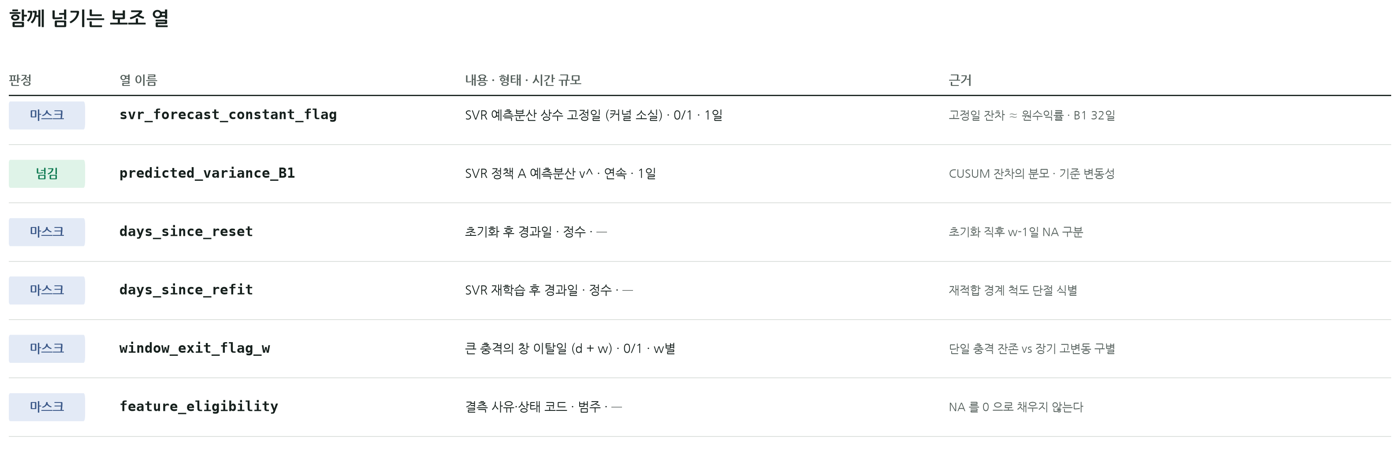

저장: research/k200_cusum_overlay_12b/figures_ae/AE02_보조열.png


In [4]:
# 표 그림 AE02 — CUSUM 과 함께 넘기는 보조 열 6개 (판정 · 이름 · 설명 · 근거).
fig = plt.figure(figsize=(16, 1.4 + 0.62 * len(SU)))  # 보조 표 그림
ax = fig.add_axes([0.01, 0.01, 0.98, 0.84])  # 표 영역
ax.set_xlim(0, 100)  # 가로 좌표
ax.set_ylim(len(SU) - 0.4, -0.9)  # 세로 좌표
ax.axis("off")  # 축 숨김
for k, (x, h) in {"v": (0, "판정"), "n": (8, "열 이름"), "d": (33, "내용 · 형태 · 시간 규모"), "w": (68, "근거")}.items():  # 머리글
    ax.text(x, -0.6, h, ha="left", va="center", fontsize=10, color=INK2, fontweight="bold")  # 열 제목
ax.plot([0, 100], [-0.35, -0.35], color=INK, lw=1)  # 머리 구분선
for i, r in SU.iterrows():  # 보조 열마다
    chip(ax, 0, i, r["verdict"], w=5.5)  # 판정
    ax.text(8, i, r["feature"], ha="left", va="center", fontsize=11, color=INK, family="monospace", fontweight="bold")  # 이름
    ax.text(33, i, f"{r['group']} · {r['form']} · {r['time_scale']}", ha="left", va="center", fontsize=10, color=INK)  # 설명
    ax.text(68, i, r["reason"].replace("−", "-"), ha="left", va="center", fontsize=9.5, color=INK2)  # 근거
    ax.plot([0, 100], [i + 0.5, i + 0.5], color=RULE, lw=0.6)  # 구분선
fig.text(0.01, 0.97, "함께 넘기는 보조 열", fontsize=16, fontweight="bold", color=INK, va="top")  # 제목
show_png(fig, FA / "AE02_보조열.png")  # 저장·표시

## 3. 요약

- **넘김 7**: SVR 잔차 CoS 20·60·120·252일, 원수익률 CoS 60일, Page 하방, SVR 예측분산. w60·원수익률 CoS 는 예측 개선이 음수라 정보를 더해서가 아니라 기준 시간 규모로 남긴다.
- **조건부 2**: X1 하방(+3.8%, 공통일 +4.5%)·양방향(+8.1%, 공통일 +2.7%). 2020-09-21 전은 NA.
- **제외 5**: Page 상방(공통일 −8.6%, 상태 표류), X1 상방, 변화점·연초 초기화 CoS(B1 과 같은 값), 21일 재학습 CoS.
- **마스크 5**: 예측분산 상수 고정 표시, 초기화·재학습 후 경과일, 창 이탈일, 결측 사유 코드.

In [5]:
# 그림에 쓴 수치를 12B 결과표에서 다시 읽어 대조한다 (피처표가 결과표와 어긋나면 실패).
fi = pd.read_csv(RES / "feature_incremental_information.csv").query("scale=='past_pct' and ~exclude_2020_train").set_index("experiment_id")  # 증분 정보
cl = pd.read_csv(RES / "agreement_clusters.csv").set_index("experiment_id")  # 값 군집
vr = pd.read_csv(RES / "annualized_volatility_response.csv").set_index("experiment_id")  # 국면 반응
bad = []  # 불일치
for _, r in CU.iterrows():  # 피처마다
    e = r["experiment_id"]  # 실험 ID
    ok = np.isclose(r["rel_mse_gain"], fi.loc[e, "rel_mse_gain_pooled"]) and int(r["cluster_size"]) == int(cl.loc[e, "value_cluster_size"]) and np.isclose(r["contrast_expanding"], vr.loc[e, "contrast_EXPANDING_minus_STABLE"])  # 세 수치 대조
    if not ok:  # 다르면
        bad.append(e)  # 기록
print(f"피처표 대조 {len(CU) - len(bad)}/{len(CU)} 일치 · 판정 {F['verdict'].value_counts().to_dict()}")  # 결과
assert not bad, bad  # 불일치면 실패
bad_p = [p for hh, p in PROT if sha(ROOT / p) != hh]  # 12번 보호 파일
assert not bad_p, bad_p  # 변경 금지

피처표 대조 13/13 일치 · 판정 {'KEEP': 7, 'DROP': 5, 'MASK': 5, 'CONDITIONAL': 2}
